# Analysis and figures

This notebook rebuilds the results section of the paper from the saved outputs: the retrieval and question-answering tables, the rank agreement between the two benchmarks, the comparison with the oracle, the human validation of answer attribution, the error analysis, and Figs 2 to 4. Nothing is rerun, so no GPU is needed and the whole notebook takes a minute or two.

By default it uses the results and annotations stored in the repository. To analyse your own run from `01_run_experiments.ipynb`, point `MAIN` and `SECOND` in the first cell at your results folders on Google Drive.

The table and figure numbers refer to the paper.

## Setup

On Colab, the cell fetches the repository from GitHub (or, if you set `REPO_URL = ""`, from `covid-rag-qa.zip` at the top of your Drive). On your own computer, open the notebook from inside the repository and the cell finds the files by itself.

In [1]:
REPO_URL = "https://github.com/Vidhvan10024/covid-rag-qa.git"   # leave empty to use covid-rag-qa.zip on your Drive instead

import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    target = "/content/covid-rag-qa"
    if not os.path.isdir(target):
        if REPO_URL:
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, target], check=True)
        else:
            from google.colab import drive
            drive.mount("/content/drive")
            with zipfile.ZipFile("/content/drive/MyDrive/covid-rag-qa.zip") as z:
                z.extractall("/content")
    os.chdir(target)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import pandas as pd
from IPython.display import Image, Markdown, display
from src import analysis as A

pd.set_option("display.width", 200)
MAIN = "results/results_full"           # primary reader, Qwen2.5-7B-Instruct
SECOND = "results/results_full_llama"   # second reader, Llama-3.1-8B-Instruct
ANNOT = "annotations"
# For your own run, for example:
# MAIN = "/content/drive/MyDrive/covid_rag_qa/results_full"
# SECOND = "/content/drive/MyDrive/covid_rag_qa/results_full_llama"
print("Working in", os.getcwd())

Working in /home/claude/release/covid-rag-qa


## Retrieval on TREC-COVID (Table 2 and H1a to H1c)

nDCG@10 is the main measure. `judged@10` is the share of the top ten documents that have a relevance judgement, and `ndcg@10_judged_only` is the score after unjudged documents are removed. The p-values come from a paired randomisation test against BM25 with Holm correction.

In [2]:
trec = pd.read_csv(f"{MAIN}/exp1_retrieval/table_retrieval.csv")
display(trec)
display(Markdown("**Hypothesis tests**"))
display(pd.read_csv(f"{MAIN}/exp1_retrieval/hypothesis_tests.csv"))
display(Markdown("**Re-ranker check** (share of judged pairs ordered correctly)"))
display(pd.read_csv(f"{MAIN}/exp1_retrieval/reranker_check.csv"))

,system,ndcg@10,precision@10,mrr@10,map@100,recall@100,R_cap@100,ndcg@10_judged_only,judged@10,p_vs_bm25(ndcg@10),sig
0,bm25,0.5887,0.636,0.8385,0.0710,0.1075,0.4670,0.6175,0.912,NaN,NaN
1,bge,0.7792,0.828,0.9180,0.1097,0.1406,0.5934,0.8343,0.914,0.0007,*
2,medcpt,0.6115,0.658,0.7937,0.0821,0.1197,0.5064,0.7242,0.792,0.6098,NaN
3,rrf(bm25+bge),0.7999,0.838,0.9533,0.1151,0.1471,0.6136,0.8056,0.994,0.0007,*
4,rrf(bm25+medcpt),0.7463,0.786,0.9460,0.1020,0.1361,0.5684,0.7608,0.968,0.0007,*
5,rrf(all),0.8074,0.850,0.9517,0.1308,0.1604,0.6626,0.8169,0.978,0.0007,*
6,bm25>>CE,0.6932,0.754,0.9158,0.0823,0.1075,0.4670,0.7221,0.930,0.0056,*
7,rrf(all)>>CE,0.7580,0.826,0.9300,0.1290,0.1604,0.6626,0.7965,0.932,0.0007,*


**Hypothesis tests**

,hypothesis,A,B,nDCG@10 A,nDCG@10 B,Δ (B-A),p (Holm),outcome
0,H1a: MedCPT > BGE,bge,medcpt,0.7792,0.6115,-0.1677,0.0006,"refuted (significant, opposite direction)"
1,H1b: RRF(all) > best single retriever (BGE),bge,rrf(all),0.7792,0.8074,0.0282,0.2161,not supported (no significant difference)
2,H1c: re-ranking improves RRF(all),rrf(all),rrf(all)>>CE,0.8074,0.7580,-0.0495,0.0540,not supported (no significant difference)


**Re-ranker check** (share of judged pairs ordered correctly)

,reranked,first_stage,judged_pairs,pairwise_acc_first_stage,pairwise_acc_reranker,judged@10_first_stage,judged@10_reranker,verdict
0,bm25>>CE,bm25,74079,0.5603,0.7033,0.912,0.930,orders judged docs better than first stage
1,rrf(all)>>CE,rrf(all),79387,0.6138,0.6063,0.978,0.932,orders judged docs worse than first stage


## Question answering on the test articles (Table 3)

One row per condition and reader. `abstained` is the share of questions answered with "insufficient evidence", and `hit@k` is the share of questions whose answer-bearing passage was among the ten passages shown. The significance tables compare every condition with BM25 (paired bootstrap for F1, McNemar's test for containment, Holm correction).

In [3]:
cols = ["condition", "f1", "em", "contains", "abstained", "hit@k", "cited"]
for label, folder in [("Qwen2.5-7B-Instruct", MAIN), ("Llama-3.1-8B-Instruct", SECOND)]:
    if os.path.exists(f"{folder}/exp2_main/summary.csv"):
        s = pd.read_csv(f"{folder}/exp2_main/summary.csv")
        display(Markdown(f"**{label}**"))
        display(s[[c for c in cols if c in s.columns]].round(4))
        display(pd.read_csv(f"{folder}/exp2_main/significance.csv"))

**Qwen2.5-7B-Instruct**

,condition,f1,em,contains,abstained,hit@k,cited
0,bge,0.3453,0.1682,0.3770,0.3365,0.6324,0.9277
1,bm25,0.4267,0.2054,0.4703,0.2682,0.7304,0.9243
2,closed_book,0.0093,0.0041,0.0061,0.9554,NaN,NaN
3,hybrid,0.4008,0.1899,0.4304,0.2493,0.7128,0.9361
4,hybrid_rerank,0.4445,0.2169,0.4845,0.2311,0.7547,0.9429
5,medcpt,0.2838,0.1297,0.2892,0.4149,0.4959,0.9365
6,oracle,0.5374,0.2507,0.6230,0.2041,1.0000,0.7131


,condition,vs,ΔF1,F1 95% CI,p_F1 (Holm),p_contains McNemar (Holm)
0,closed_book,bm25,-0.4174,"[-0.439, -0.396]",0.0006,0.0000
1,oracle,bm25,0.1107,"[0.089, 0.133]",0.0006,0.0000
2,bge,bm25,-0.0814,"[-0.100, -0.063]",0.0006,0.0000
3,medcpt,bm25,-0.1428,"[-0.164, -0.123]",0.0006,0.0000
4,hybrid,bm25,-0.0259,"[-0.043, -0.009]",0.0066,0.0010
5,hybrid_rerank,bm25,0.0178,"[0.002, 0.034]",0.0312,0.2031


**Llama-3.1-8B-Instruct**

,condition,f1,em,contains,abstained,hit@k,cited
0,bge,0.4270,0.1851,0.4669,0.0459,0.6324,0.9497
1,bm25,0.4831,0.2189,0.5392,0.0514,0.7304,0.9309
2,closed_book,0.0609,0.0135,0.0318,0.6243,NaN,NaN
3,hybrid,0.4748,0.2081,0.5128,0.0264,0.7128,0.9362
4,hybrid_rerank,0.5054,0.2203,0.5649,0.0365,0.7547,0.9369
5,medcpt,0.3558,0.1358,0.3709,0.0797,0.4959,0.9479
6,oracle,0.6225,0.2973,0.7453,0.0432,1.0000,0.6608


,condition,vs,ΔF1,F1 95% CI,p_F1 (Holm),p_contains McNemar (Holm)
0,closed_book,bm25,-0.4221,"[-0.443, -0.401]",0.0006,0.0000
1,oracle,bm25,0.1394,"[0.118, 0.161]",0.0006,0.0000
2,bge,bm25,-0.0560,"[-0.075, -0.037]",0.0006,0.0000
3,medcpt,bm25,-0.1273,"[-0.148, -0.107]",0.0006,0.0000
4,hybrid,bm25,-0.0083,"[-0.025, 0.008]",0.3274,0.0411
5,hybrid_rerank,bm25,0.0224,"[0.007, 0.038]",0.0094,0.0411


## Do the two benchmarks rank the pipelines the same way? (Section 5.4, Fig. 3)

The first table gives each pipeline's score on both benchmarks; the second gives Kendall's τ between the rankings. With five pipelines τ can only take a few values, so it is descriptive: τ = 1.00 means the same order, τ = 0.00 no relation.

In [4]:
scores, taus = A.rank_agreement(MAIN, SECOND if os.path.exists(SECOND) else None)
display(scores)
display(taus)

,TREC nDCG@10,TREC nDCG@10 (judged only),COVID-QA hit@10,F1 (primary reader),F1 (second reader)
BM25,0.5887,0.6175,0.7304,0.4267,0.4831
BGE,0.7792,0.8343,0.6324,0.3453,0.4270
MedCPT,0.6115,0.7242,0.4959,0.2838,0.3558
Hybrid,0.8074,0.8169,0.7128,0.4008,0.4748
Hybrid + rerank,0.7580,0.7965,0.7547,0.4445,0.5054


,ranking A,ranking B,Kendall tau,p (exact)
0,COVID-QA hit@10,F1 (primary reader),1.0,0.017
1,TREC nDCG@10,F1 (primary reader),0.0,1.000
2,TREC nDCG@10,COVID-QA hit@10,0.0,1.000
3,TREC nDCG@10 (judged only),F1 (primary reader),-0.2,0.817
4,COVID-QA hit@10,F1 (second reader),1.0,0.017
5,TREC nDCG@10,F1 (second reader),0.0,1.000
6,F1 (primary reader),F1 (second reader),1.0,0.017


## Retrieval failures or reading failures? (Table 4)

For each pipeline, F1 on the questions where it retrieved the answer-bearing passage is compared with the oracle's F1 on exactly those questions. `equivalent` is the result of two one-sided tests with a margin of ±0.05 F1. `F1_miss` is the pipeline's F1 on the questions where retrieval failed.

In [5]:
for label, folder in [("Qwen2.5-7B-Instruct", MAIN), ("Llama-3.1-8B-Instruct", SECOND)]:
    p = f"{folder}/exp2_main/transfer_vs_oracle.csv"
    if os.path.exists(p):
        display(Markdown(f"**{label}**"))
        display(pd.read_csv(p))

**Qwen2.5-7B-Instruct**

,condition,n_hit,F1_hit,oracle_F1_same_q,Δ(c-oracle),95% CI,90% CI (TOST),equivalent (±0.05),n_miss,F1_miss,p_diff (Holm)
0,bm25,1081,0.5640,0.5689,-0.0049,"[-0.029, 0.018]","[-0.025, 0.015]",True,399,0.0546,1.0000
1,bge,936,0.5124,0.5449,-0.0325,"[-0.057, -0.007]","[-0.054, -0.011]",False,544,0.0578,0.0615
2,medcpt,734,0.5158,0.5325,-0.0167,"[-0.047, 0.013]","[-0.042, 0.008]",True,746,0.0557,1.0000
3,hybrid,1055,0.5289,0.5422,-0.0133,"[-0.038, 0.011]","[-0.034, 0.007]",True,425,0.0828,1.0000
4,hybrid_rerank,1117,0.5603,0.5585,0.0018,"[-0.021, 0.024]","[-0.018, 0.021]",True,363,0.0881,1.0000


**Llama-3.1-8B-Instruct**

,condition,n_hit,F1_hit,oracle_F1_same_q,Δ(c-oracle),95% CI,90% CI (TOST),equivalent (±0.05),n_miss,F1_miss,p_diff (Holm)
0,bm25,1081,0.6252,0.6430,-0.0178,"[-0.039, 0.003]","[-0.035, -0.000]",True,399,0.0979,0.2208
1,bge,936,0.6140,0.6358,-0.0219,"[-0.045, 0.001]","[-0.041, -0.003]",True,544,0.1054,0.2208
2,medcpt,734,0.6103,0.6400,-0.0297,"[-0.055, -0.003]","[-0.052, -0.008]",False,746,0.1054,0.1295
3,hybrid,1055,0.6108,0.6319,-0.0210,"[-0.042, 0.001]","[-0.039, -0.003]",True,425,0.1370,0.2208
4,hybrid_rerank,1117,0.6284,0.6426,-0.0142,"[-0.035, 0.006]","[-0.031, 0.003]",True,363,0.1270,0.2208


## Human validation of answer attribution (Table 5)

Two annotators judged independently whether the cited passages support each of 102 answers. Agreement is Cohen's κ with a bootstrap 95% interval. The five disagreements were then settled together, giving the final labels, against which the automatic NLI score is checked (agreement and κ at a threshold of 0.5, and the area under the ROC curve).

In [6]:
hv = A.human_validation(f"{ANNOT}/faithfulness_validation.csv")
k, lo, hi = hv["kappa_annotators"]
print(f"Annotators agreed on {hv['annotators_agree']} of {hv['n_items']} answers; Cohen's kappa = {k:.2f} [{lo:.2f}, {hi:.2f}]")
print(f"Supported after resolving disagreements: {hv['supported_final']} of {hv['n_items']}")
k, lo, hi = hv["kappa_nli"]
print(f"NLI score at 0.5: agreement {hv['nli_agreement']:.3f}, kappa = {k:.2f} [{lo:.2f}, {hi:.2f}], AUC = {hv['nli_auc']:.2f}")
print(f"Mean NLI score: {hv['nli_mean_supported']:.3f} for supported, {hv['nli_mean_unsupported']:.3f} for unsupported answers")
print(f"Supported answers scored below 0.5: {hv['supported_but_below_threshold']}; "
      f"unsupported answers scored 0.5 or above: {hv['unsupported_but_above_threshold']}")
display(hv["table"])
display(Markdown("**How the disagreements were settled**"))
display(pd.read_csv(f"{ANNOT}/faithfulness_disagreements.csv"))

Annotators agreed on 97 of 102 answers; Cohen's kappa = 0.80 [0.59, 0.95]
Supported after resolving disagreements: 86 of 102
NLI score at 0.5: agreement 0.784, kappa = 0.40 [0.20, 0.59], AUC = 0.83
Mean NLI score: 0.772 for supported, 0.285 for unsupported answers
Supported answers scored below 0.5: 18; unsupported answers scored 0.5 or above: 4


,supported (final),annotator A,annotator B
Oracle,15/17 (0.88),0.88,1.00
BM25,16/17 (0.94),0.94,0.94
BGE,12/17 (0.71),0.71,0.71
MedCPT,12/17 (0.71),0.71,0.76
Hybrid,15/17 (0.88),0.88,0.94
Hybrid + rerank,16/17 (0.94),0.94,0.88
All sampled answers,86/102 (0.84),0.84,0.87


**How the disagreements were settled**

,item,label_A,label_B,final_label,reason,resolved_on,resolved_by
0,F022,No,Yes,No,Rule 3 (partly supported): the passage lists c...,2026-10-17,"annotators A and B, jointly"
1,F028,No,Yes,No,Rule 3 (partly supported): contact and close c...,2026-10-18,"annotators A and B, jointly"
2,F058,No,Yes,No,Rule 1 (judge only the passage shown): the cit...,2026-10-17,"annotators A and B, jointly"
3,F060,No,Yes,No,Rule 3 (partly supported): the passage names f...,2026-10-19,"annotators A and B, jointly"
4,F081,Yes,No,Yes,Supported: the meaning of alert level 6 is sta...,2026-10-18,"annotators A and B, jointly"


## Error analysis (Table 6)

Main cause of 50 randomly sampled wrong answers of the best pipeline, and of 25 cases where BGE retrieved the answer-bearing passage but the answer was wrong while the oracle's was right. Brackets give Wilson 95% intervals.

In [7]:
display(A.error_table(f"{ANNOT}/error_analysis_best_pipeline.csv", f"{ANNOT}/error_analysis_bge_distractors.csv"))

,"Best pipeline (hybrid + rerank), n = 50","BGE with answer retrieved, oracle correct, n = 25"
Wrongly declined,17 (34%) [22%–48%],10 (40%) [23%–59%]
Retrieval miss,15 (30%) [19%–44%],0
Extraction error,8 (16%) [8%–29%],6 (24%) [11%–43%]
Wrong passage used,5 (10%) [4%–21%],2 (8%) [2%–25%]
Correct but scored wrong,5 (10%) [4%–21%],7 (28%) [14%–48%]
Gold answer problem,0,0
Other,0,0
Distractor passage present,–,16 (64%)


## Figures 2 to 4

Drawn from the same files and saved as PNG (600 dpi) and TIFF in `paper_figures`. They are meant to be readable in greyscale, so line styles, markers and hatching carry the distinctions rather than colour.

**Fig2_ablation.png**

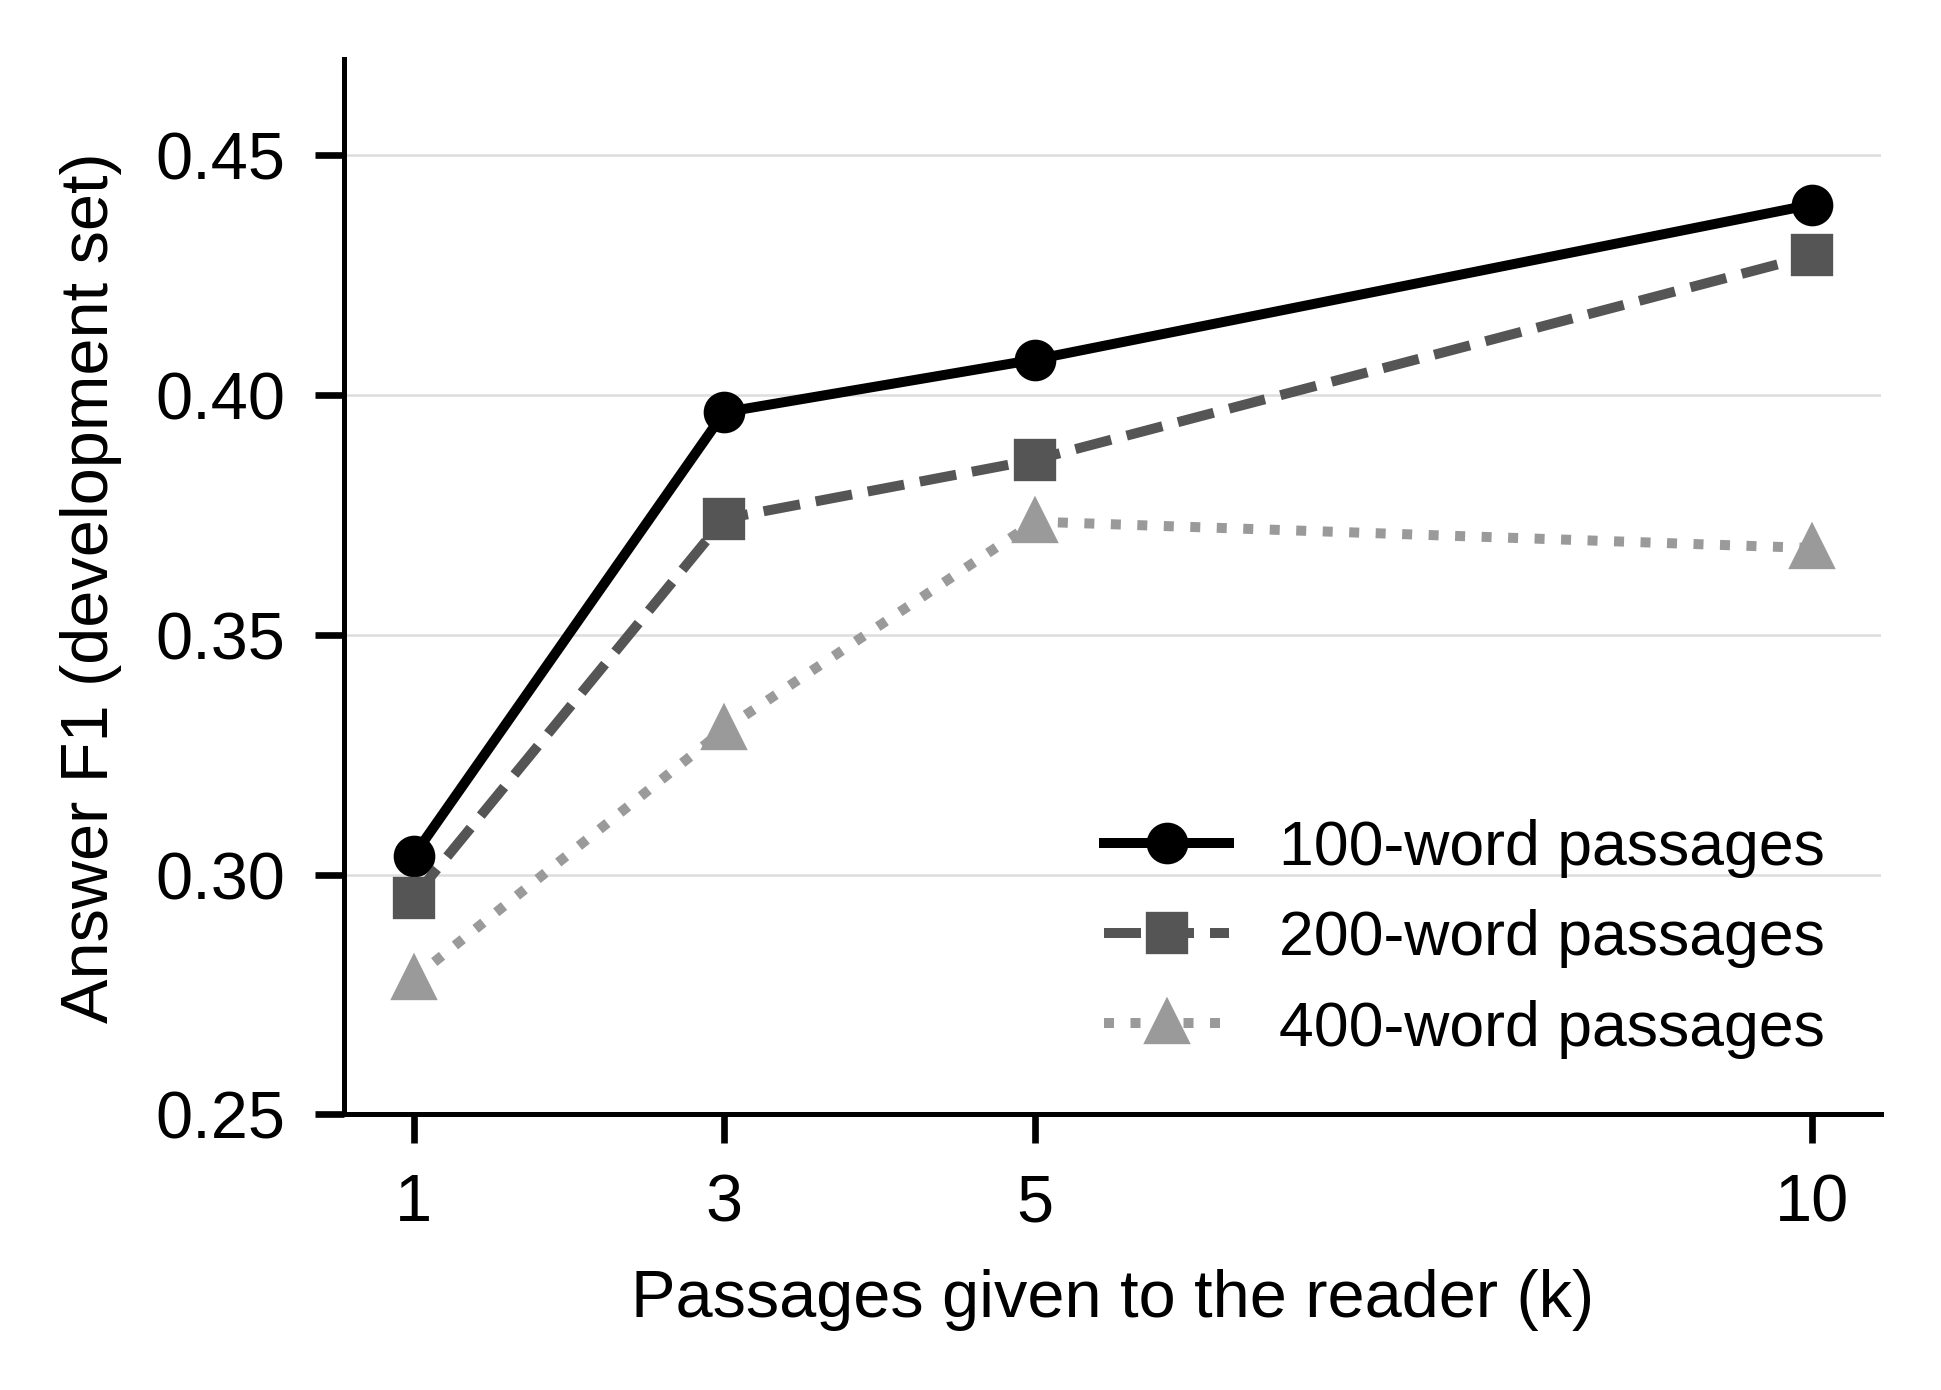

**Fig3_rank_comparison.png**

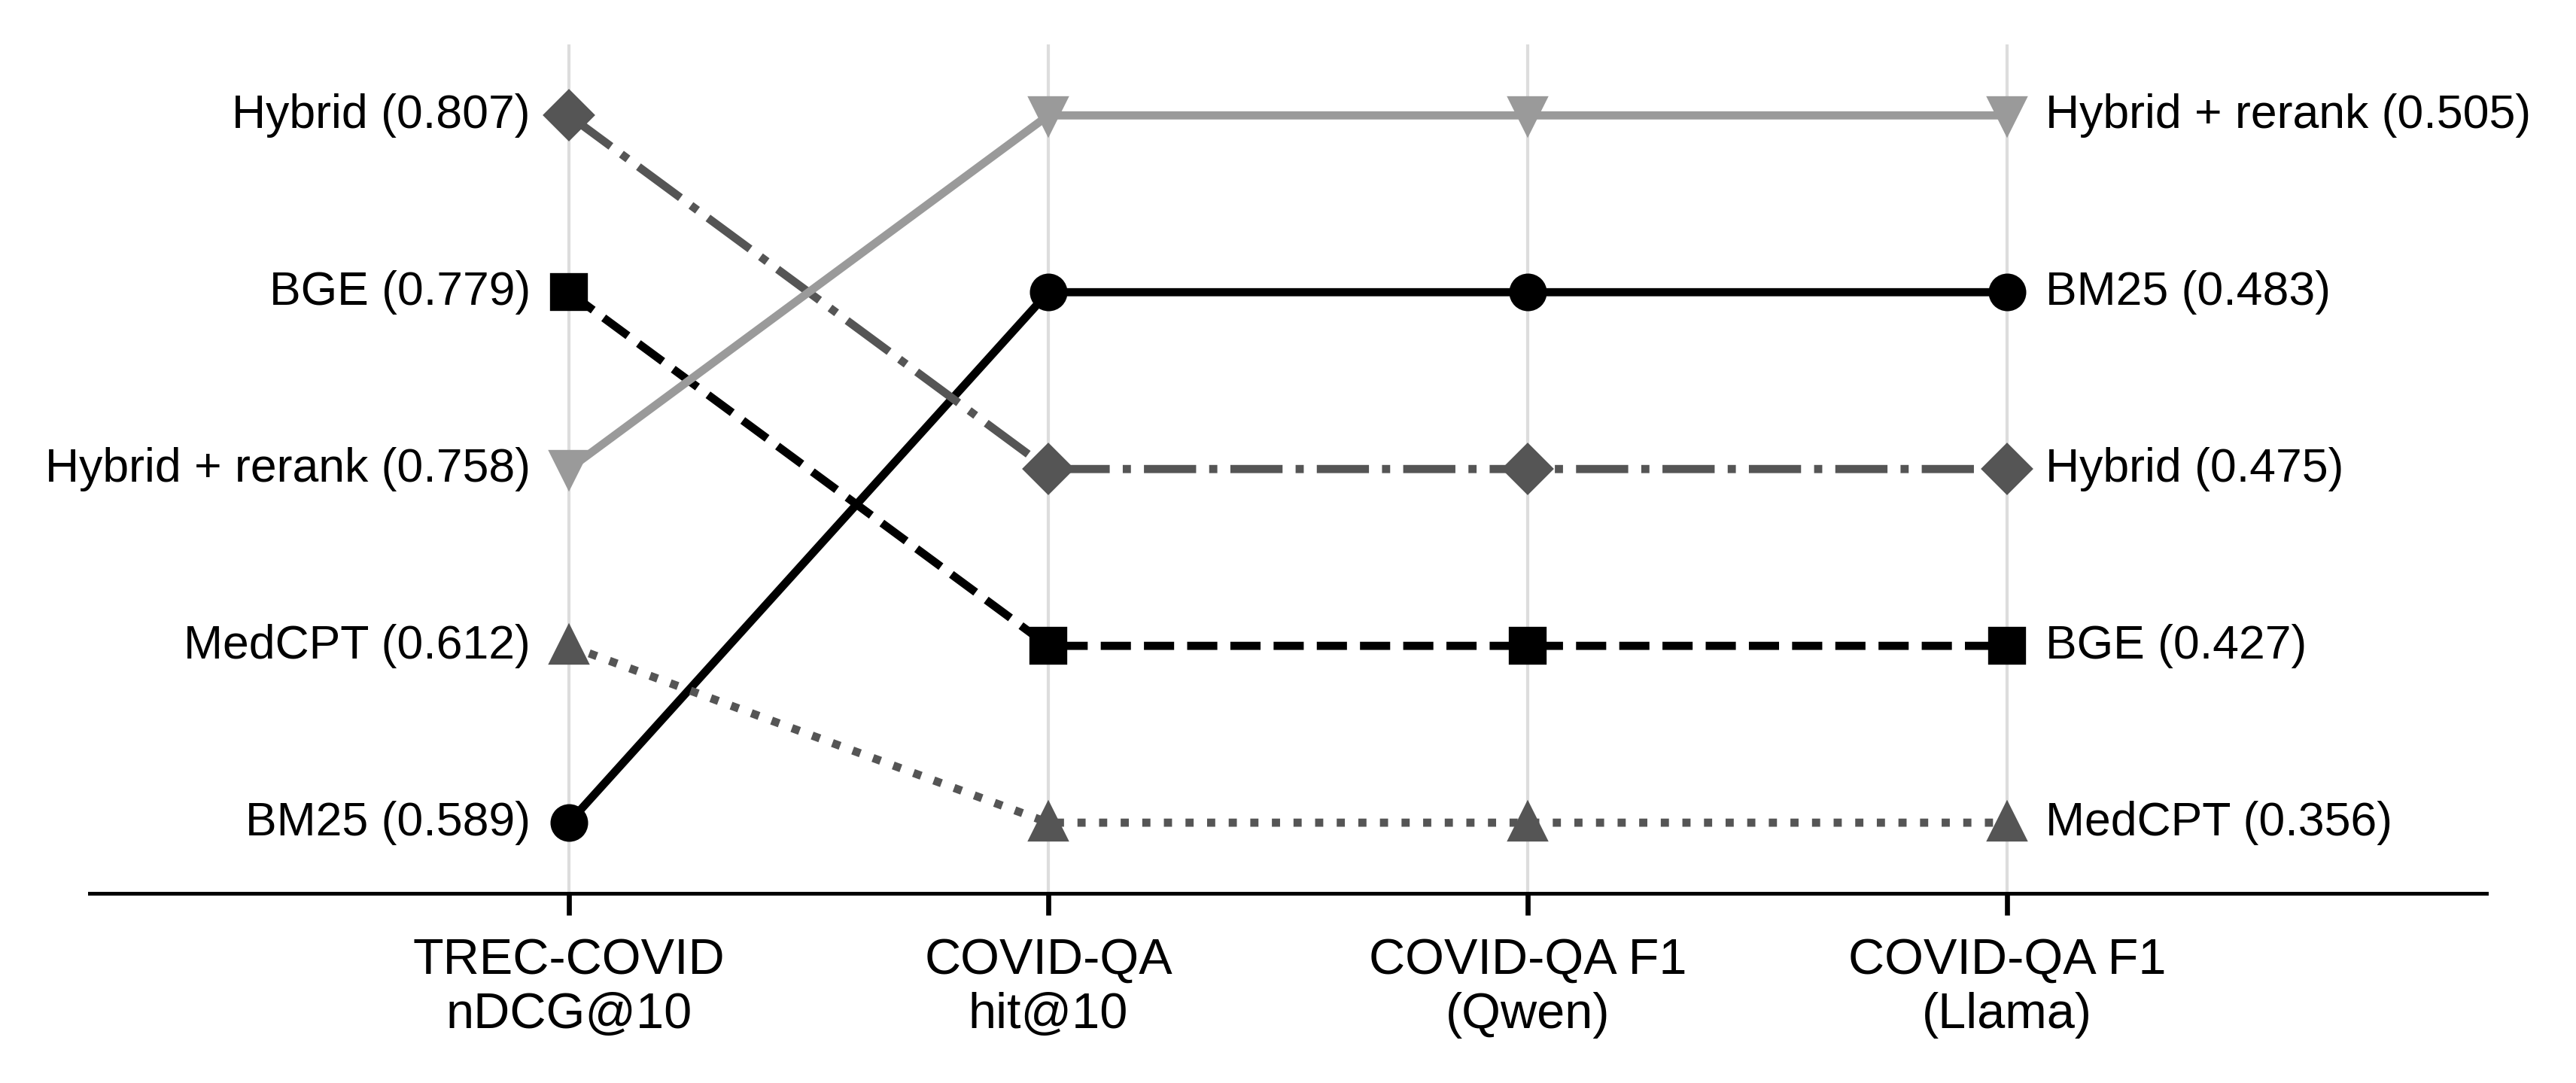

**Fig4_retrieved_vs_missed.png**

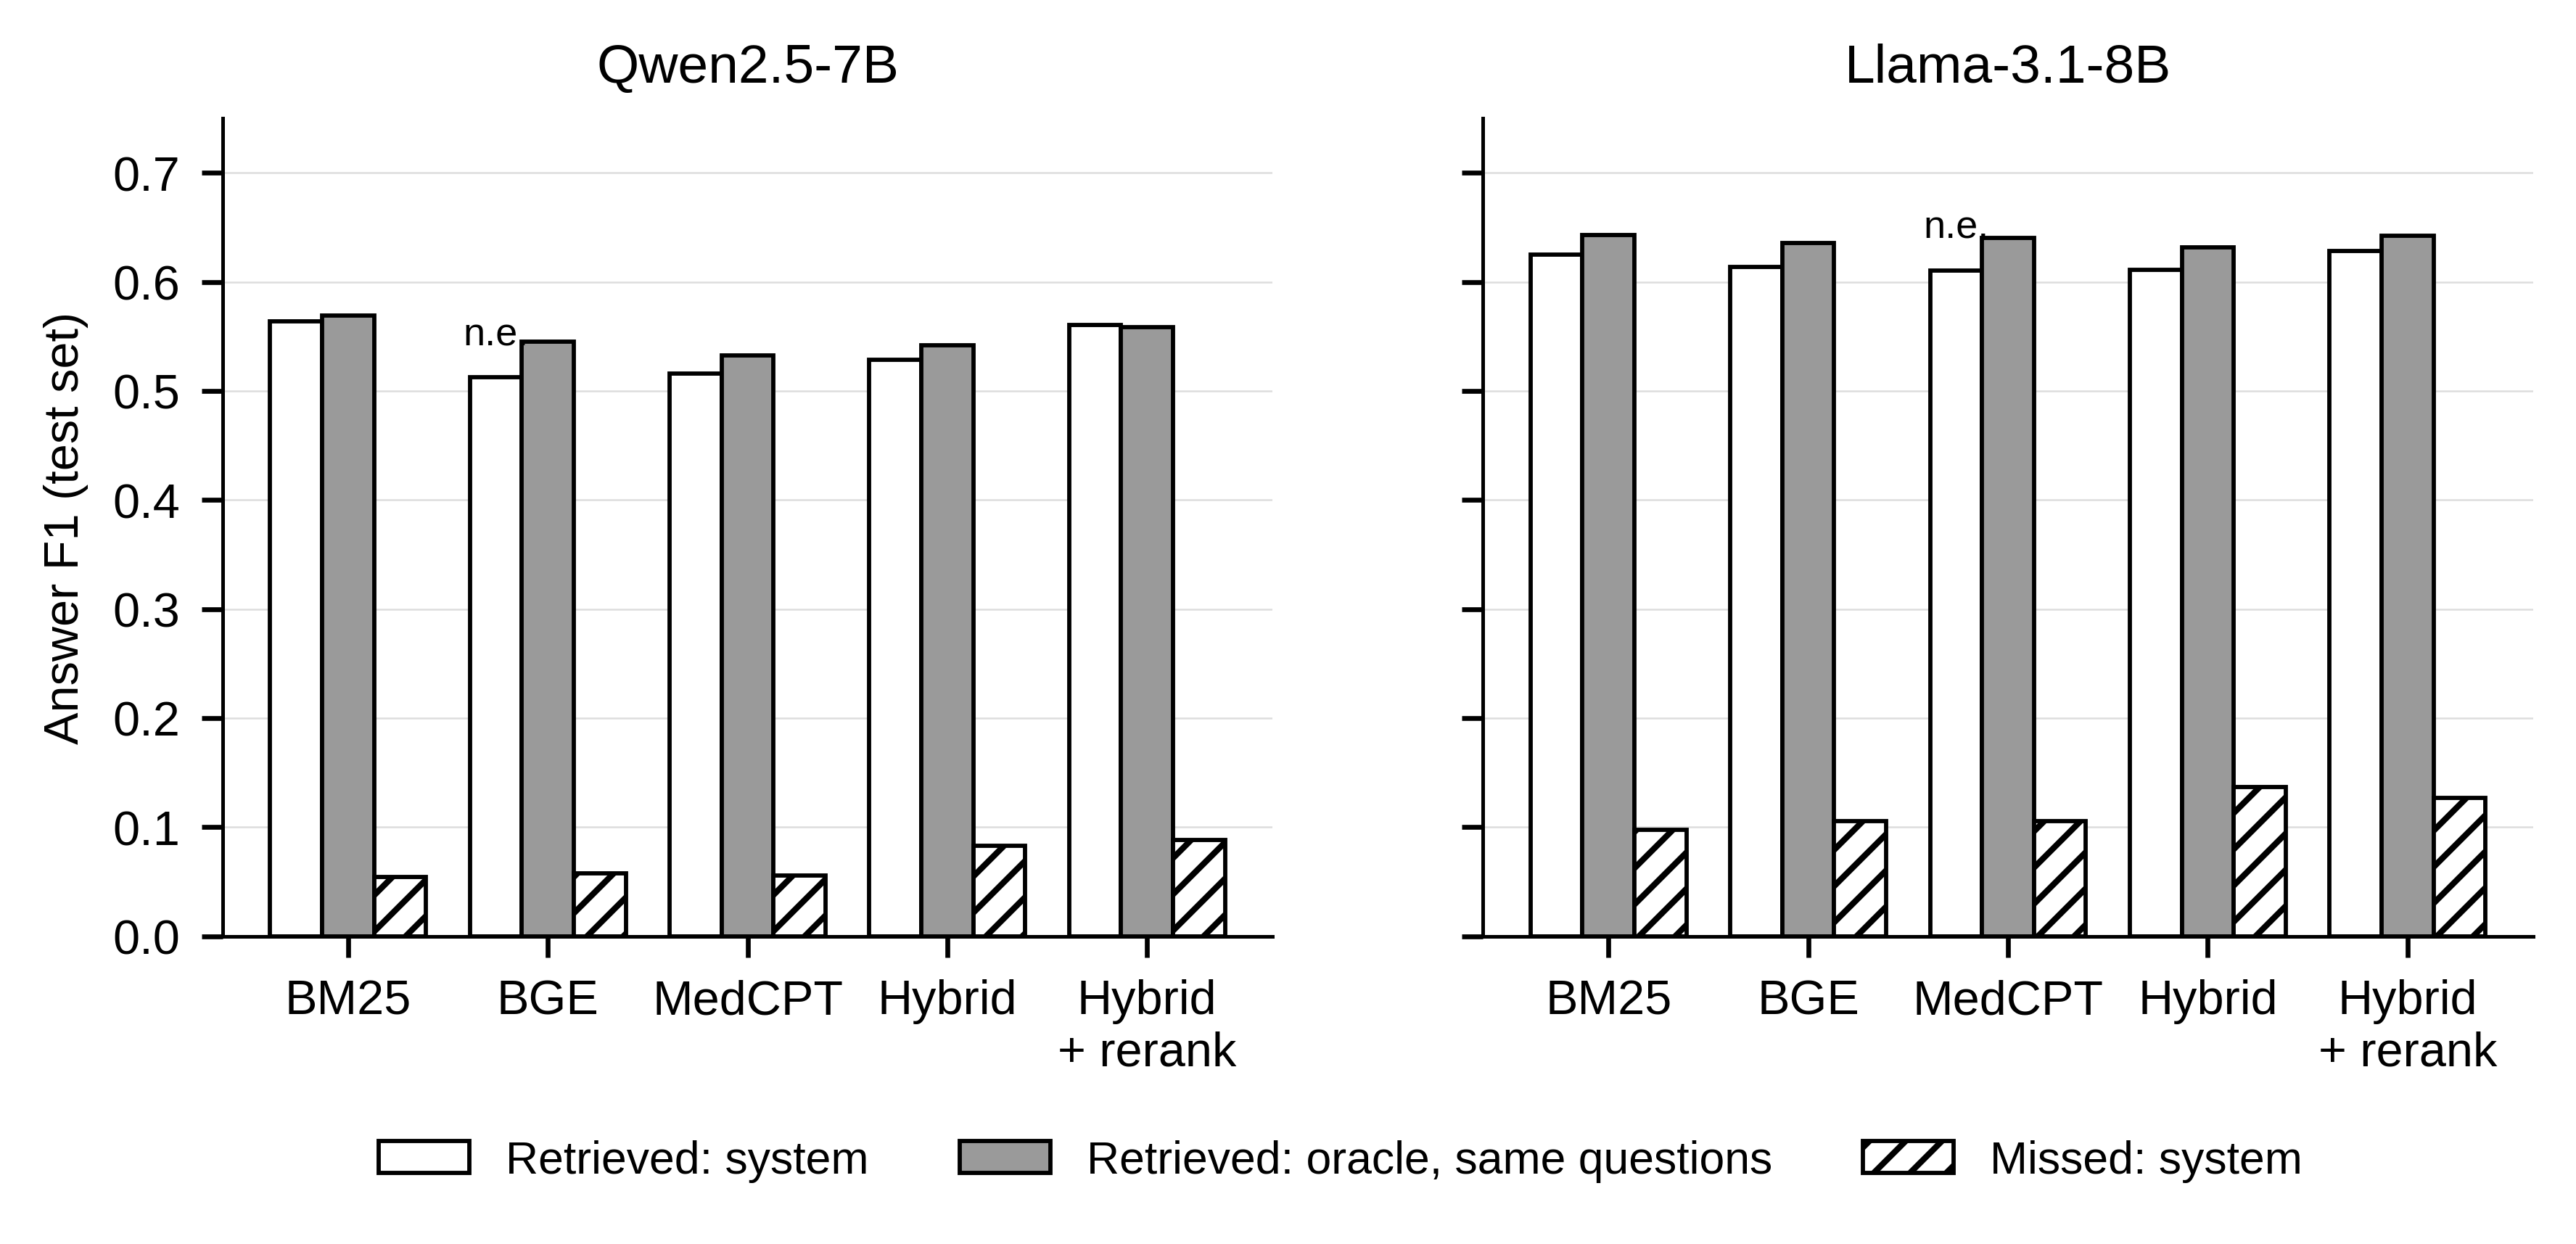

In [8]:
from src.paper_figures import make_all
for p in make_all(MAIN, SECOND if os.path.exists(SECOND) else None, "paper_figures"):
    display(Markdown(f"**{os.path.basename(p)}**"))
    display(Image(p, width=720))

## Where the numbers appear in the paper

| Output above | In the paper |
|---|---|
| TREC-COVID table, hypothesis tests, re-ranker check | Table 2, Section 5.1, Table 7 (H1a to H1c) |
| Question-answering tables | Table 3, Section 5.3 |
| Rank agreement | Section 5.4, Fig. 3 |
| Comparison with the oracle | Table 4, Fig. 4 |
| Human validation | Table 5, Section 5.5 |
| Error analysis | Table 6, Section 5.6 |
| Passage-length ablation (`results_full/exp3_ablation/summary.csv`) | Fig. 2, Section 5.2 |